In [1]:
from pathlib import Path
from datasets import load_from_disk

PROJECT_ROOT = Path.cwd().parent

dataset = load_from_disk(
    PROJECT_ROOT/"datasets/landmark_recognition"
)

# Inspecting the Data 

In [2]:
print(dataset)
print()
print(dataset['train'].features)
print()
sample = dataset["train"][0]
print(sample.keys())

DatasetDict({
    train: Dataset({
        features: ['id', 'landmark_id', 'category', 'image', 'label'],
        num_rows: 36463
    })
    test: Dataset({
        features: ['id', 'landmark_id', 'category', 'image', 'label'],
        num_rows: 9116
    })
})

{'id': Value('string'), 'landmark_id': Value('int64'), 'category': Value('string'), 'image': Image(mode=None, decode=True), 'label': Value('int64')}

dict_keys(['id', 'landmark_id', 'category', 'image', 'label'])


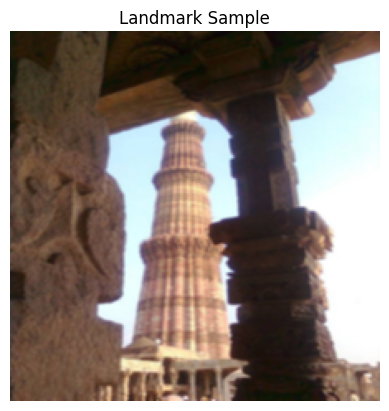

In [3]:
import matplotlib.pyplot as plt

sample = dataset["train"][0]

image = sample["image"]

plt.imshow(image)
plt.axis("off")
plt.title("Landmark Sample")
plt.show()

In [4]:
from collections import Counter

categories = dataset["train"]["category"]

class_distribution = Counter(categories)

for category, count in class_distribution.most_common():
    print(category, ":", count)

Media_contributed_by_the_ETH-Bibliothek : 5043
Corktown,_Toronto : 1784
Noraduz_Cemetery : 1392
Museum_of_Folk_Architecture_and_Ethnography_in_Pyrohiv : 1387
Sal%C3%A8ve : 924
Lviv : 892
Nieuwe_Waterweg : 865
Niagara_Falls : 786
Pe%C5%A1ter : 768
Khotyn_Fortress : 768
Feroz_Shah_Kotla : 740
Haleakal%C4%81_National_Park : 735
Golden_Gate_Bridge : 723
Catedral_San_Sebasti%C3%A1n,_Cochabamba : 722
Grand_Canyon : 710
Madrid_R%C3%ADo : 682
Kecharis : 665
Hayravank_monastery : 658
Mathura_Museum : 647
Qutb_Minar_and_its_monuments,_Delhi : 620
St._Lawrence,_Toronto : 611
Sofiyivsky_Park : 605
Genoese_fortress_(Sudak) : 595
Akkerman_fortress : 594
Eiffel_Tower : 584
Skopje_Fortress : 571
Edinburgh_Castle : 569
Masada : 541
Purana_Qila : 539
Matka_Canyon : 528
Pakistan_Monument_Islamabad : 519
Haghpat : 485
Itmad-Ud-Daulah's_Tomb : 484
Faisal_Mosque : 483
York_River_State_Park : 471
Saint_Holy_Mother_church_of_Yeghvard : 469
Douthat_State_Park : 453
Grote_of_Onze-Lieve-Vrouwekerk_(Breda) : 449


```
There is class imbalance in this dataset
over the epochs model may get more about the Media_contributed_by_the_ETH-Bibliothek
it do get less info about the Isa_Khan_Niyazi's_tomb : 384

so our idea is keeping 500 per landmark
if its less than 500 we do the augmentation 

# Data Preprocessing

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split

train_data = dataset["train"]

categories = train_data["category"]

train_indices, val_indices = train_test_split(
    np.arange(len(train_data)),
    test_size=0.10,
    random_state=42,
    stratify=categories
)

train_split = train_data.select(train_indices.tolist())
val_split = train_data.select(val_indices.tolist())

print("Original training images:", len(train_data))
print("New training images:", len(train_split))
print("Validation images:", len(val_split))

Original training images: 36463
New training images: 32816
Validation images: 3647


In [6]:
# Prepare category-wise indices

from collections import defaultdict

category_to_indices = defaultdict(list)

for index, category in enumerate(train_split["category"]):
    category_to_indices[category].append(index)

print("Total categories:", len(category_to_indices))

Total categories: 51


In [7]:
# Balance the training dataset

rng = np.random.default_rng(42)

balanced_indices = []

TARGET_IMAGES = 500

for category, indices in category_to_indices.items():

    selected_indices = rng.choice(
        indices,
        size=TARGET_IMAGES,
        replace=len(indices) < TARGET_IMAGES
    )

    balanced_indices.extend(selected_indices.tolist())

rng.shuffle(balanced_indices)

balanced_train_data = train_split.select(
    balanced_indices
)

print("Balanced training samples:", len(balanced_train_data))

Balanced training samples: 25500


In [8]:
# Verify the class distribution

balanced_distribution = Counter(
    balanced_train_data["category"]
)

print("Total categories:", len(balanced_distribution))
print("Total images:", sum(balanced_distribution.values()))

for category, count in sorted(balanced_distribution.items()):
    print(f"{category}: {count}")

Total categories: 51
Total images: 25500
%C3%87ufut_Qale: 500
Akbar's_Tomb: 500
Akkerman_fortress: 500
Catedral_San_Sebasti%C3%A1n,_Cochabamba: 500
Corktown,_Toronto: 500
Douthat_State_Park: 500
Edinburgh_Castle: 500
Eiffel_Tower: 500
Episcopal_Diocese_of_Southwest_Florida: 500
Faisal_Mosque: 500
Feroz_Shah_Kotla: 500
Genoese_fortress_(Sudak): 500
Golden_Gate_Bridge: 500
Grand_Canyon: 500
Grote_of_Onze-Lieve-Vrouwekerk_(Breda): 500
Haghpat: 500
Haleakal%C4%81_National_Park: 500
Harichavank: 500
Hayravank_monastery: 500
Isa_Khan_Niyazi's_tomb: 500
Itmad-Ud-Daulah's_Tomb: 500
Jurassic_Coast: 500
Kecharis: 500
Khotyn_Fortress: 500
Lake_Como: 500
Ljubljana_Castle: 500
Lviv: 500
Madrid_R%C3%ADo: 500
Masada: 500
Mathura_Museum: 500
Matka_Canyon: 500
Media_contributed_by_the_ETH-Bibliothek: 500
Museum_of_Folk_Architecture_and_Ethnography_in_Pyrohiv: 500
Niagara_Falls: 500
Nieuwe_Waterweg: 500
Noraduz_Cemetery: 500
Nyhavn: 500
Ogrodzieniec_Castle: 500
Pakistan_Monument_Islamabad: 500
Pe%C5%A1t

In [9]:
import torch
import torchvision.transforms as transforms

from PIL import Image
import matplotlib.pyplot as plt

In [10]:
train_transform = transforms.Compose([

    transforms.RandomResizedCrop(
        224,
        scale=(0.85, 1.0)
    ),

    transforms.RandomHorizontalFlip(
        p=0.3
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15,
        hue=0.03
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])

In [11]:
val_transform = transforms.Compose([

    transforms.Resize(256),

    transforms.CenterCrop(224),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )

])

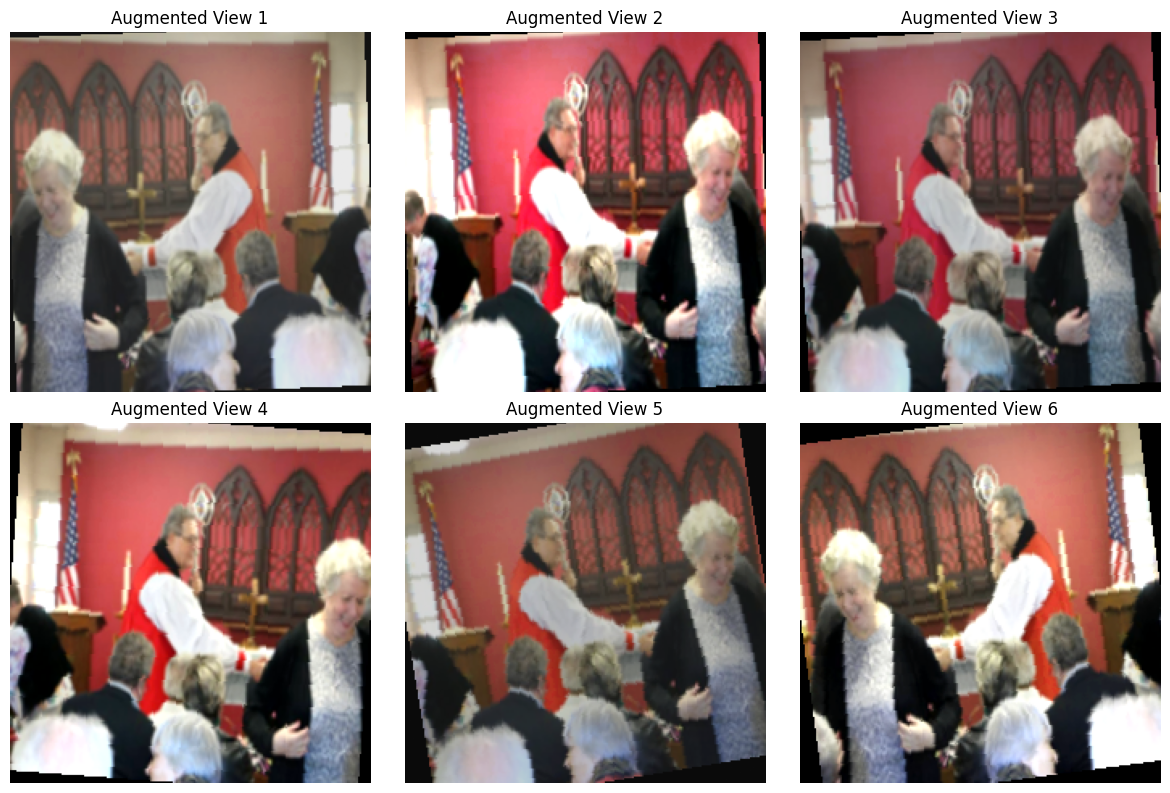

In [12]:
# visulalizing the transformation 

sample = balanced_train_data[0]

original_image = sample["image"].convert("RGB")

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flatten()):

    augmented_image = train_transform(
        original_image
    )

    # Undo ImageNet normalization for visualization
    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    display_image = augmented_image * std + mean

    display_image = display_image.clamp(0, 1)

    display_image = display_image.permute(1, 2, 0)

    ax.imshow(display_image)
    ax.set_title(f"Augmented View {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
categories = sorted(
    balanced_train_data.unique("category")
)

category_to_label = {
    category: index
    for index, category in enumerate(categories)
}

label_to_category = {
    index: category
    for category, index in category_to_label.items()
}

print("Total classes:", len(category_to_label))
print()

for key,value in label_to_category.items():
    print(f"{key:3}-->{value}")
    

Total classes: 51

  0-->%C3%87ufut_Qale
  1-->Akbar's_Tomb
  2-->Akkerman_fortress
  3-->Catedral_San_Sebasti%C3%A1n,_Cochabamba
  4-->Corktown,_Toronto
  5-->Douthat_State_Park
  6-->Edinburgh_Castle
  7-->Eiffel_Tower
  8-->Episcopal_Diocese_of_Southwest_Florida
  9-->Faisal_Mosque
 10-->Feroz_Shah_Kotla
 11-->Genoese_fortress_(Sudak)
 12-->Golden_Gate_Bridge
 13-->Grand_Canyon
 14-->Grote_of_Onze-Lieve-Vrouwekerk_(Breda)
 15-->Haghpat
 16-->Haleakal%C4%81_National_Park
 17-->Harichavank
 18-->Hayravank_monastery
 19-->Isa_Khan_Niyazi's_tomb
 20-->Itmad-Ud-Daulah's_Tomb
 21-->Jurassic_Coast
 22-->Kecharis
 23-->Khotyn_Fortress
 24-->Lake_Como
 25-->Ljubljana_Castle
 26-->Lviv
 27-->Madrid_R%C3%ADo
 28-->Masada
 29-->Mathura_Museum
 30-->Matka_Canyon
 31-->Media_contributed_by_the_ETH-Bibliothek
 32-->Museum_of_Folk_Architecture_and_Ethnography_in_Pyrohiv
 33-->Niagara_Falls
 34-->Nieuwe_Waterweg
 35-->Noraduz_Cemetery
 36-->Nyhavn
 37-->Ogrodzieniec_Castle
 38-->Pakistan_Monument_Is

In [14]:
import torch
from torch.utils.data import Dataset

class LandmarkDataset(Dataset):

    def __init__(
        self,
        hf_dataset,
        category_to_label,
        transform=None
    ):

        self.dataset = hf_dataset
        self.category_to_label = category_to_label
        self.transform = transform

    def __len__(self):

        return len(self.dataset)

    def __getitem__(self, index):

        sample = self.dataset[index]

        image = sample["image"].convert("RGB")

        category = sample["category"]

        label = self.category_to_label[category]

        if self.transform is not None:
            image = self.transform(image)

        return image, torch.tensor(
            label,
            dtype=torch.long
        )

In [15]:
train_dataset = LandmarkDataset(
    hf_dataset=balanced_train_data,
    category_to_label=category_to_label,
    transform=train_transform
)

val_dataset = LandmarkDataset(
    hf_dataset=val_split,
    category_to_label=category_to_label,
    transform=val_transform
)

In [16]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [17]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

In [18]:
%%writefile "$PROJECT_ROOT/src/preprocessing.py"




import numpy as np
import torch
import torchvision.transforms as transforms

from collections import defaultdict, Counter
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader


# -----------------------------------------
# 1. DATASET CLASS
# -----------------------------------------

class LandmarkDataset(Dataset):

    def __init__(
        self,
        hf_dataset,
        category_to_label,
        transform=None
    ):
        self.dataset = hf_dataset
        self.category_to_label = category_to_label
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):

        sample = self.dataset[index]

        image = sample["image"].convert("RGB")
        category = sample["category"]

        label = self.category_to_label[category]

        if self.transform is not None:
            image = self.transform(image)

        return image, torch.tensor(
            label,
            dtype=torch.long
        )


# -----------------------------------------
# 2. PREPROCESSING FUNCTION
# -----------------------------------------

def preprocessing(
    dataset,
    target_images=500,
    batch_size=32,
    val_size=0.10,
    random_state=42
):

    # -------------------------------------
    # Train-validation split
    # -------------------------------------

    train_data = dataset["train"]

    categories = train_data["category"]

    train_indices, val_indices = train_test_split(
        np.arange(len(train_data)),
        test_size=val_size,
        random_state=random_state,
        stratify=categories
    )

    train_split = train_data.select(
        train_indices.tolist()
    )

    val_split = train_data.select(
        val_indices.tolist()
    )

    print("Original training samples:", len(train_data))
    print("Training samples:", len(train_split))
    print("Validation samples:", len(val_split))


    # -------------------------------------
    # Balance training dataset
    # -------------------------------------

    category_to_indices = defaultdict(list)

    for index, category in enumerate(train_split["category"]):
        category_to_indices[category].append(index)

    rng = np.random.default_rng(random_state)

    balanced_indices = []

    for category, indices in category_to_indices.items():

        selected_indices = rng.choice(
            indices,
            size=target_images,
            replace=len(indices) < target_images
        )

        balanced_indices.extend(
            selected_indices.tolist()
        )

    rng.shuffle(balanced_indices)

    balanced_train_data = train_split.select(
        balanced_indices
    )

    balanced_distribution = Counter(
        balanced_train_data["category"]
    )

    print("\nBalanced training samples:", len(balanced_train_data))
    print("Number of classes:", len(balanced_distribution))

    print("\nClass distribution:")

    for category, count in sorted(balanced_distribution.items()):
        print(f"{category}: {count}")


    # -------------------------------------
    # Training augmentation
    # -------------------------------------

    train_transform = transforms.Compose([

        transforms.RandomResizedCrop(
            224,
            scale=(0.85, 1.0)
        ),

        transforms.RandomHorizontalFlip(
            p=0.3
        ),

        transforms.RandomRotation(
            degrees=10
        ),

        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.15,
            hue=0.03
        ),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    ])


    # -------------------------------------
    # Validation preprocessing
    # -------------------------------------

    val_transform = transforms.Compose([

        transforms.Resize(256),

        transforms.CenterCrop(224),

        transforms.ToTensor(),

        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    ])


    # -------------------------------------
    # Label encoding
    # -------------------------------------

    categories = sorted(
        balanced_train_data.unique("category")
    )

    category_to_label = {
        category: index
        for index, category in enumerate(categories)
    }

    label_to_category = {
        index: category
        for category, index in category_to_label.items()
    }


    # -------------------------------------
    # Create PyTorch datasets
    # -------------------------------------

    train_dataset = LandmarkDataset(
        hf_dataset=balanced_train_data,
        category_to_label=category_to_label,
        transform=train_transform
    )

    val_dataset = LandmarkDataset(
        hf_dataset=val_split,
        category_to_label=category_to_label,
        transform=val_transform
    )


    # -------------------------------------
    # Create DataLoaders
    # -------------------------------------

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    print("\nPreprocessing completed!")
    print("Train batches:", len(train_loader))
    print("Validation batches:", len(val_loader))

    return (
    train_loader,
    val_loader,
    category_to_label,
    label_to_category
    )

Overwriting Y:\Python\AI ML\Month 2\week 8-NLP\46 — LANDMARK RECOGNITION/src/preprocessing.py
